In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("original_dataset.csv")
df

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,39,Female,Married,Bachelor's,39640.08,3303.34,Employed,0.275,691,16322.23,...,36,566.22,C5,2,23748.10,5801.45,1,0,4,0
19996,66,Female,Married,Bachelor's,32062.90,2671.91,Employed,0.367,758,16697.34,...,36,553.71,B5,8,49929.65,40901.31,3,0,3,1
19997,65,Female,Single,Master's,18642.02,1553.50,Student,0.106,751,23924.78,...,36,772.66,B4,3,13137.57,5075.67,1,0,2,1
19998,35,Male,Married,Master's,22181.39,1848.45,Retired,0.275,646,16920.13,...,36,595.36,D2,5,19580.82,3876.16,4,0,5,1


# EDA

In [3]:
df.head()

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [4]:
df.shape

(20000, 22)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   20000 non-null  int64  
 1   gender                20000 non-null  str    
 2   marital_status        20000 non-null  str    
 3   education_level       20000 non-null  str    
 4   annual_income         20000 non-null  float64
 5   monthly_income        20000 non-null  float64
 6   employment_status     20000 non-null  str    
 7   debt_to_income_ratio  20000 non-null  float64
 8   credit_score          20000 non-null  int64  
 9   loan_amount           20000 non-null  float64
 10  loan_purpose          20000 non-null  str    
 11  interest_rate         20000 non-null  float64
 12  loan_term             20000 non-null  int64  
 13  installment           20000 non-null  float64
 14  grade_subgrade        20000 non-null  str    
 15  num_of_open_accounts  20000 no

In [6]:
df.describe()

,age,annual_income,monthly_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_term,installment,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,48.027000,43549.637766,3629.136466,0.177019,679.25695,15129.300909,12.400626,43.22280,455.625794,5.011800,48649.824769,24333.394631,1.990150,0.061800,2.489150,0.799900
std,15.829352,28668.579671,2389.048326,0.105059,69.63858,8605.405513,2.442729,11.00838,274.622125,2.244529,32423.378128,22313.845395,1.474945,0.285105,1.631384,0.400085
min,21.000000,6000.000000,500.000000,0.010000,373.00000,500.000000,3.140000,36.00000,9.430000,0.000000,6157.800000,496.350000,0.000000,0.000000,0.000000,0.000000
25%,35.000000,24260.752500,2021.730000,0.096000,632.00000,8852.695000,10.740000,36.00000,253.910000,3.000000,27180.492500,9592.572500,1.000000,0.000000,1.000000,1.000000
50%,48.000000,36585.260000,3048.770000,0.160000,680.00000,14946.170000,12.400000,36.00000,435.595000,5.000000,40241.615000,18334.555000,2.000000,0.000000,2.000000,1.000000
75%,62.000000,54677.917500,4556.495000,0.241000,727.00000,20998.867500,14.002500,60.00000,633.595000,6.000000,60361.257500,31743.327500,3.000000,0.000000,3.000000,1.000000
max,75.000000,400000.000000,33333.330000,0.667000,850.00000,49039.690000,22.510000,60.00000,1685.400000,15.000000,454394.190000,352177.900000,11.000000,2.000000,11.000000,1.000000


In [7]:
df.isnull().sum()

age                     0
gender                  0
marital_status          0
education_level         0
annual_income           0
monthly_income          0
employment_status       0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
loan_purpose            0
interest_rate           0
loan_term               0
installment             0
grade_subgrade          0
num_of_open_accounts    0
total_credit_limit      0
current_balance         0
delinquency_history     0
public_records          0
num_of_delinquencies    0
loan_paid_back          0
dtype: int64

In [8]:
df.columns

Index(['age', 'gender', 'marital_status', 'education_level', 'annual_income',
       'monthly_income', 'employment_status', 'debt_to_income_ratio',
       'credit_score', 'loan_amount', 'loan_purpose', 'interest_rate',
       'loan_term', 'installment', 'grade_subgrade', 'num_of_open_accounts',
       'total_credit_limit', 'current_balance', 'delinquency_history',
       'public_records', 'num_of_delinquencies', 'loan_paid_back'],
      dtype='str')

<Axes: xlabel='loan_term', ylabel='count'>

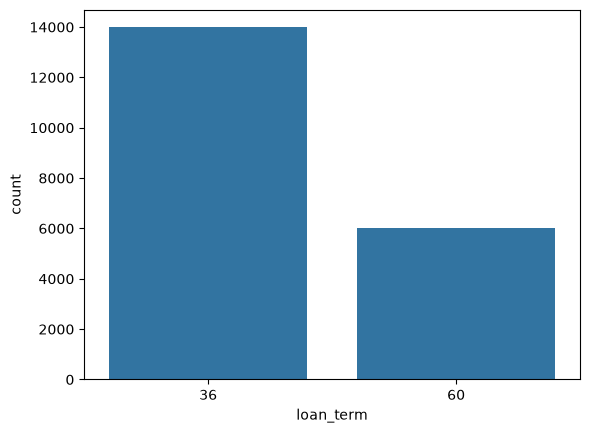

In [9]:
sns.countplot(x=df["loan_term"])

<Axes: xlabel='employment_status', ylabel='count'>

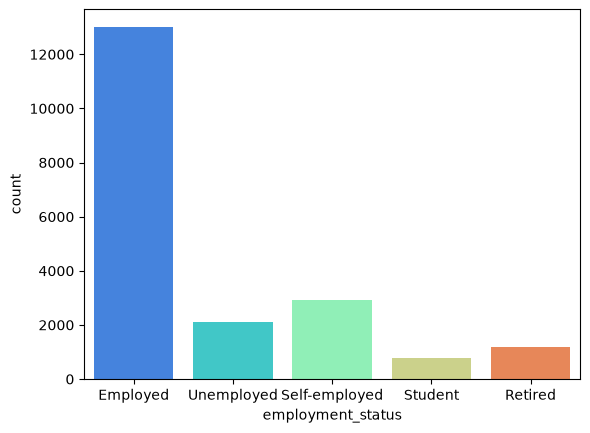

In [10]:
sns.countplot(x=df["employment_status"],palette='rainbow')

<Axes: ylabel='education_level'>

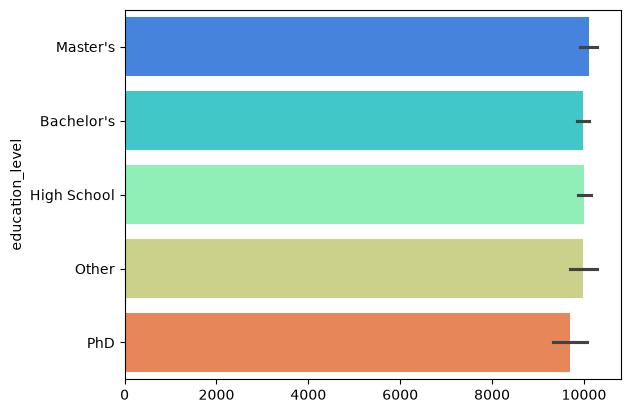

In [11]:
sns.barplot(df["education_level"],palette='rainbow')

<Axes: ylabel='debt_to_income_ratio'>

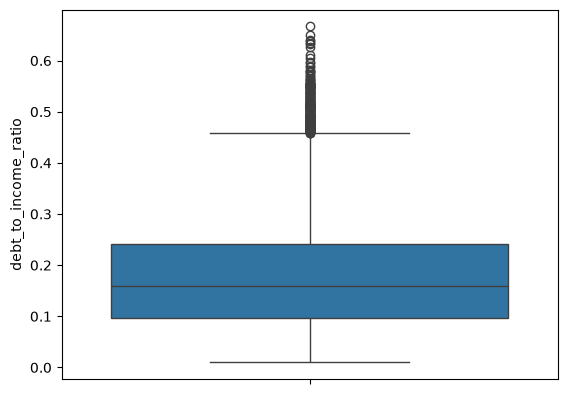

In [12]:
sns.boxplot(df["debt_to_income_ratio"])

<Axes: ylabel='credit_score'>

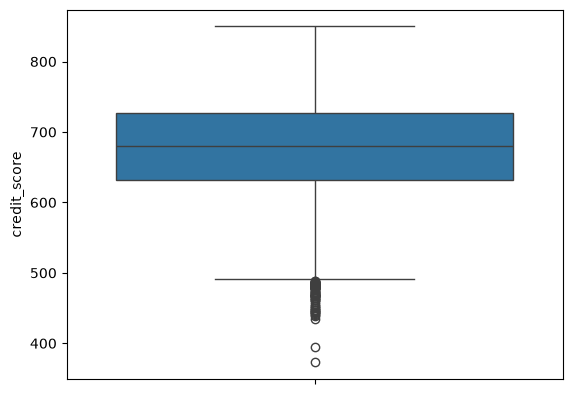

In [13]:
sns.boxplot(df["credit_score"])

<Axes: xlabel='loan_paid_back'>

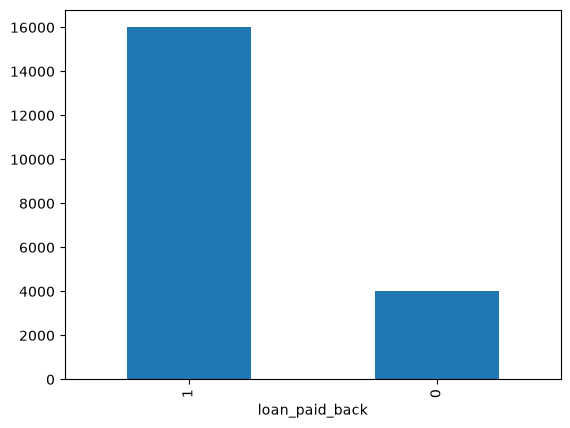

In [14]:
df["loan_paid_back"].value_counts().plot(kind='bar')

<Axes: xlabel='monthly_income', ylabel='Count'>

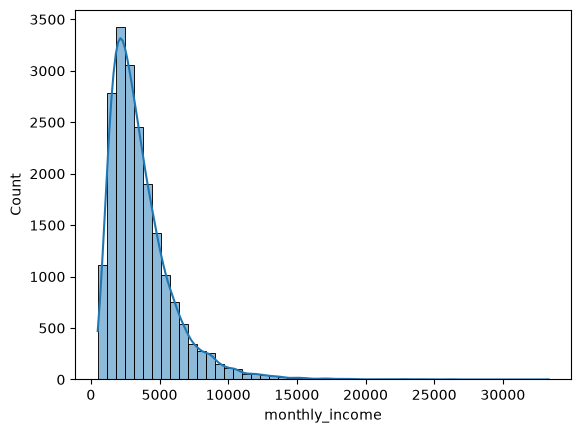

In [15]:
sns.histplot(df["monthly_income"],bins=50,kde=True)

<Axes: xlabel='annual_income', ylabel='Count'>

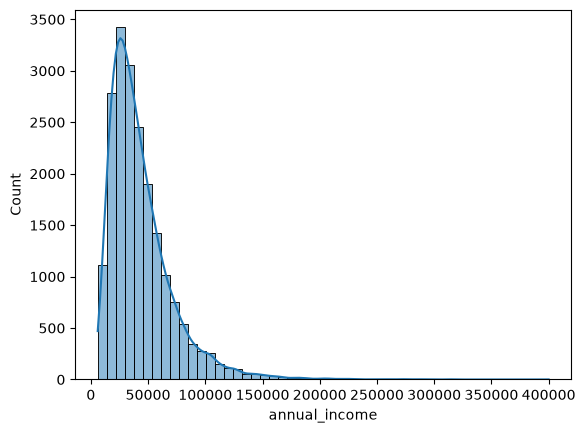

In [16]:
sns.histplot(df["annual_income"],bins=50,kde=True)

<Axes: xlabel='credit_score', ylabel='Count'>

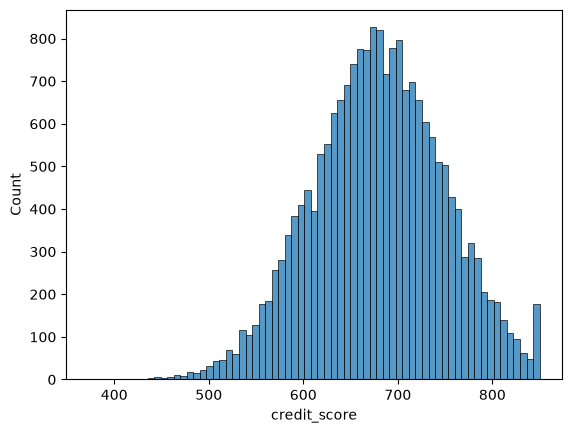

In [17]:
sns.histplot(df["credit_score"])

<Axes: >

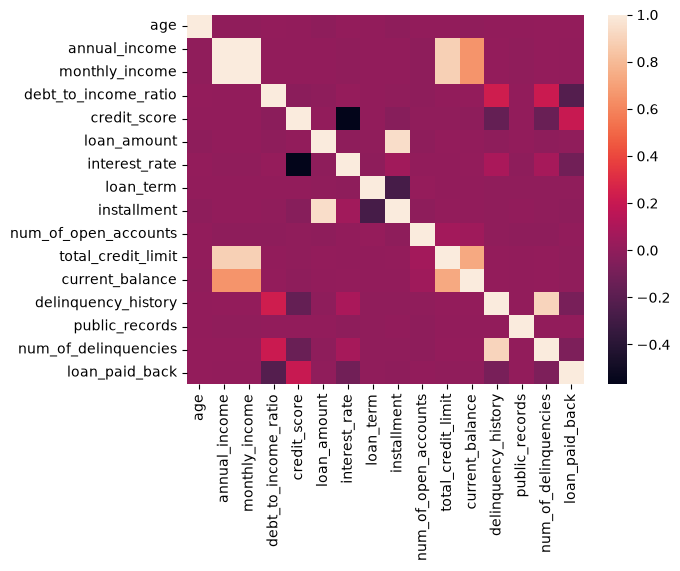

In [18]:
sns.heatmap(df.corr(numeric_only=True))

<Axes: ylabel='loan_amount'>

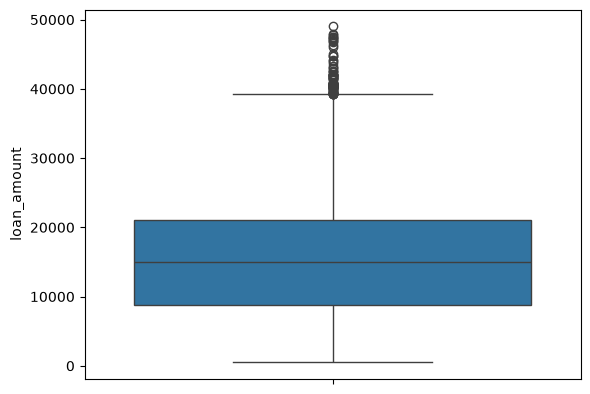

In [19]:
sns.boxplot(df['loan_amount'])

<Axes: xlabel='delinquency_history', ylabel='num_of_delinquencies'>

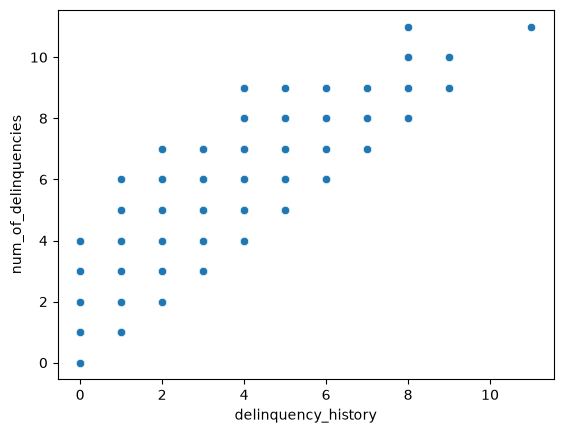

In [20]:
sns.scatterplot(data=df,x='delinquency_history',y='num_of_delinquencies')

<Axes: xlabel='annual_income', ylabel='loan_amount'>

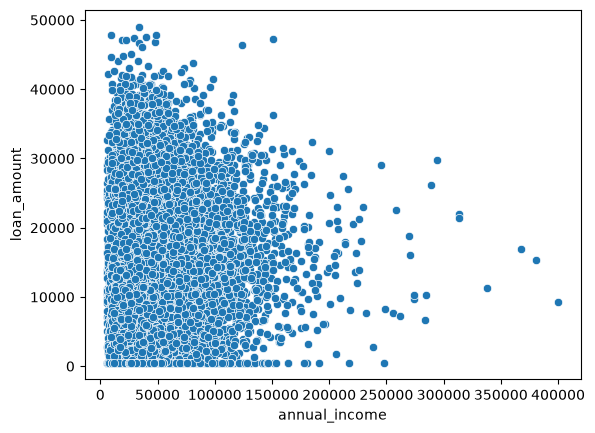

In [21]:
sns.scatterplot(data=df,x='annual_income',y='loan_amount')

In [22]:
df["loan_purpose"].value_counts().head(1)

loan_purpose
Debt consolidation    7981
Name: count, dtype: int64

In [23]:
df["employment_status"].value_counts().head(1)

employment_status
Employed    13007
Name: count, dtype: int64

<Axes: xlabel='loan_term', ylabel='loan_amount'>

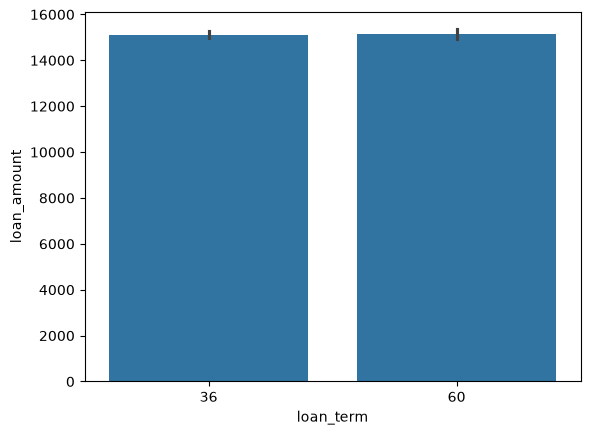

In [24]:
sns.barplot(data=df,y='loan_amount',x='loan_term')

<Axes: xlabel='loan_paid_back', ylabel='employment_status'>

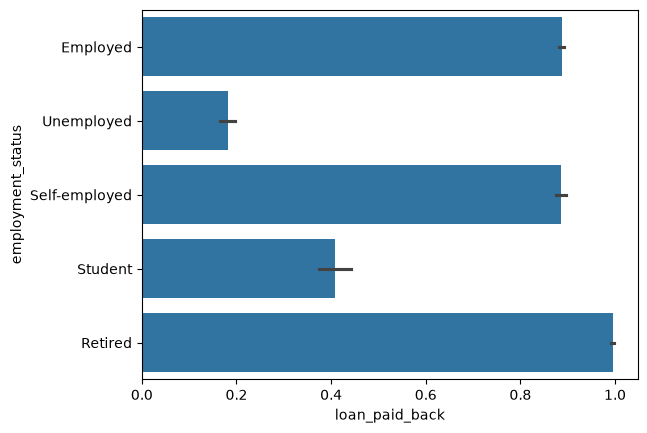

In [25]:
sns.barplot(data=df,x=df["loan_paid_back"],y=df["employment_status"])

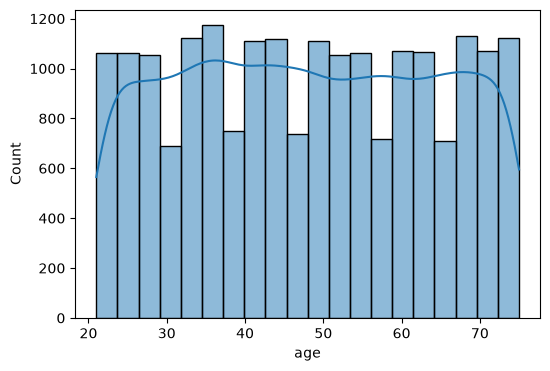

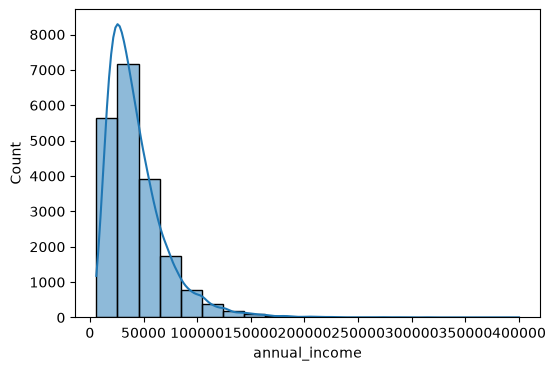

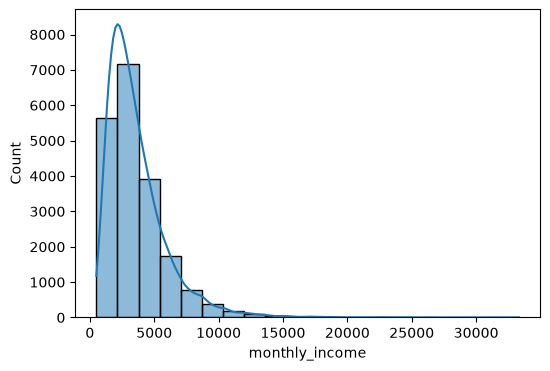

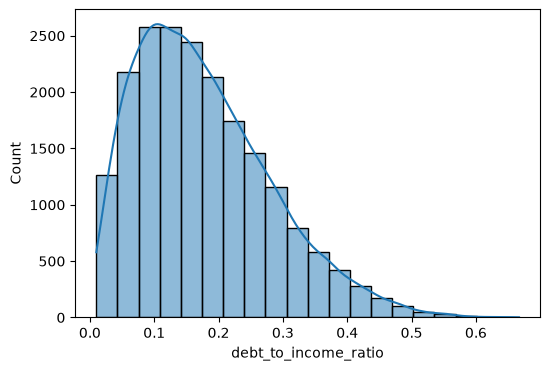

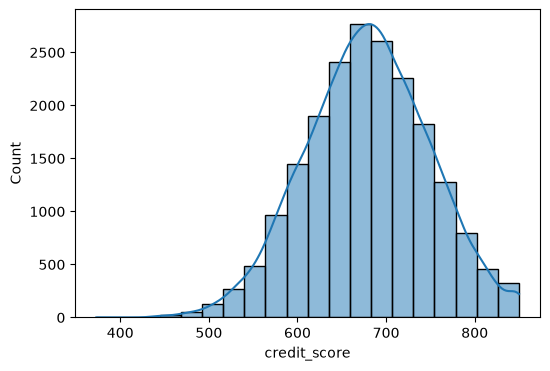

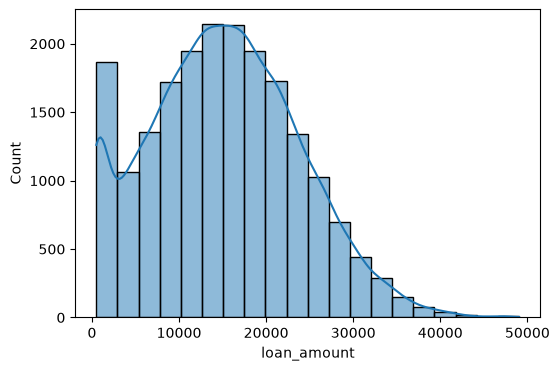

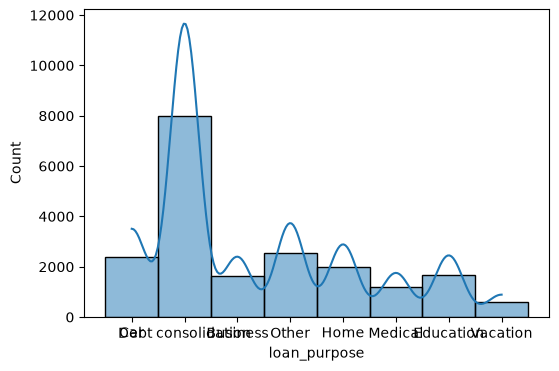

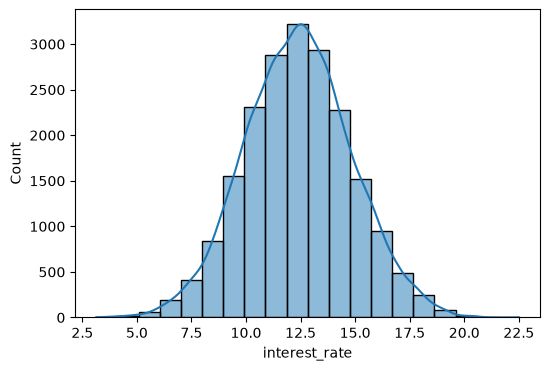

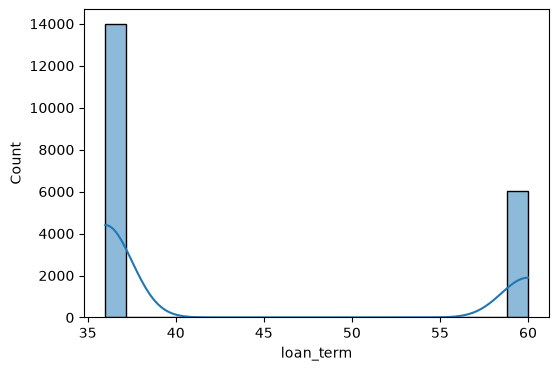

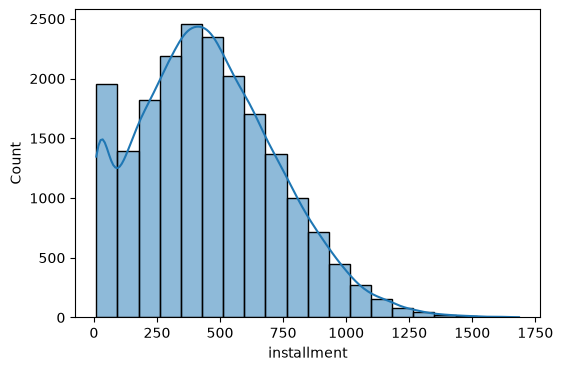

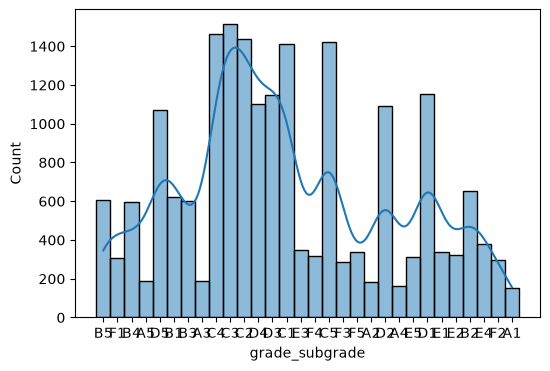

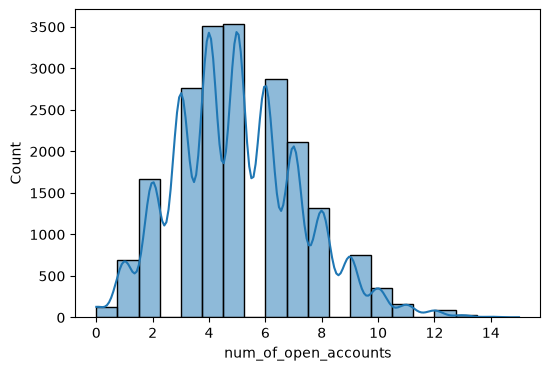

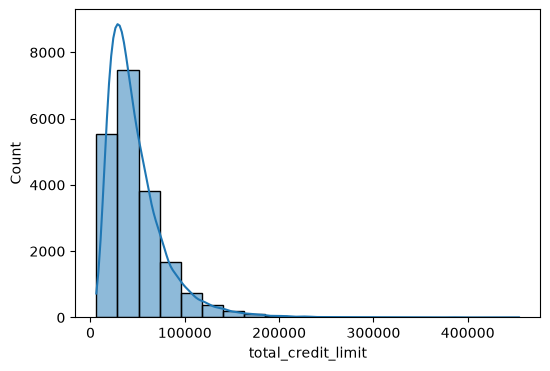

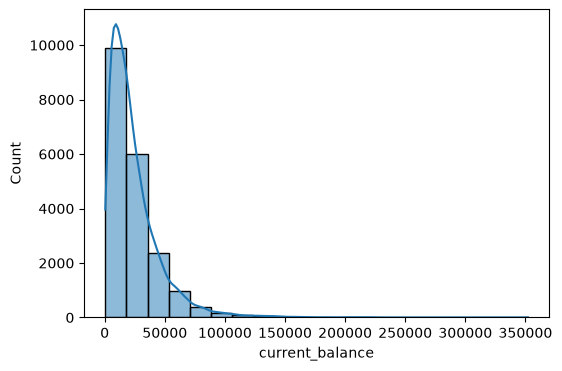

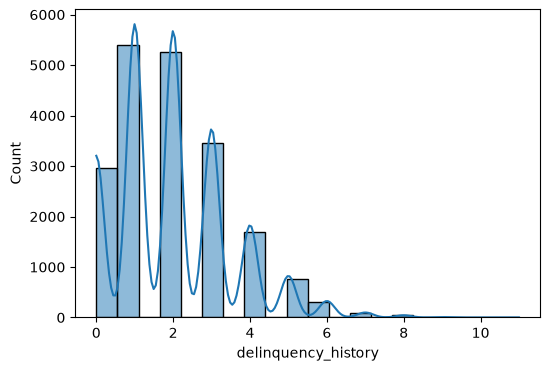

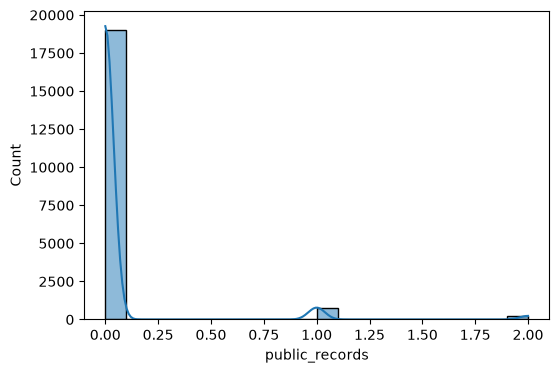

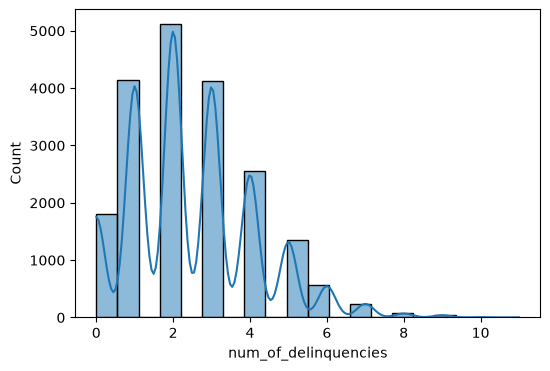

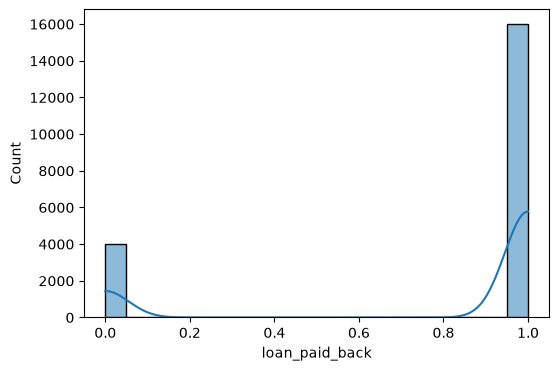

In [26]:
numerical_col=['age','annual_income','monthly_income','debt_to_income_ratio','credit_score','loan_amount','loan_purpose','interest_rate','loan_term',
               'installment','grade_subgrade','num_of_open_accounts','total_credit_limit','current_balance','delinquency_history','public_records',
               'num_of_delinquencies','loan_paid_back']
for col in numerical_col:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True,bins=20)

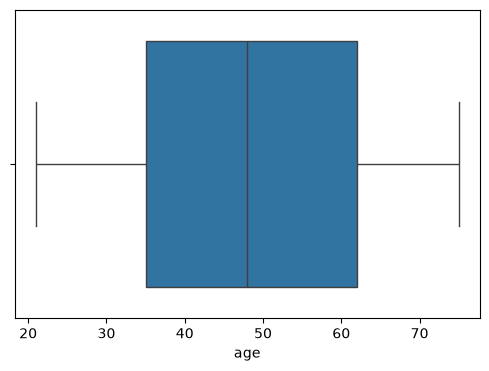

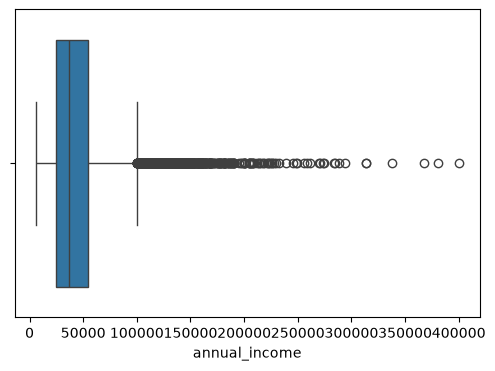

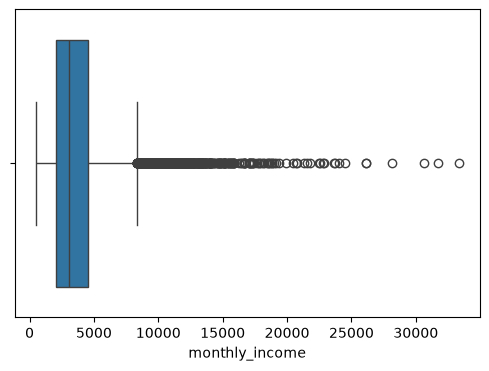

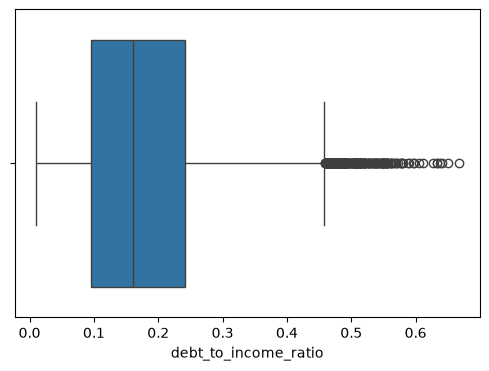

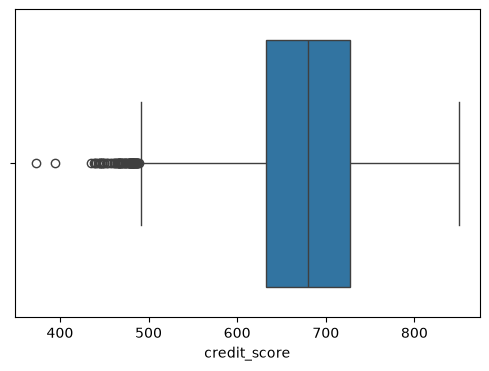

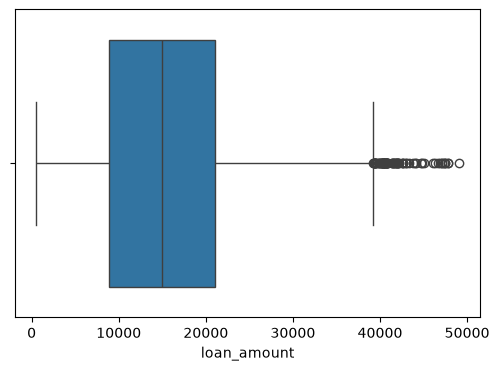

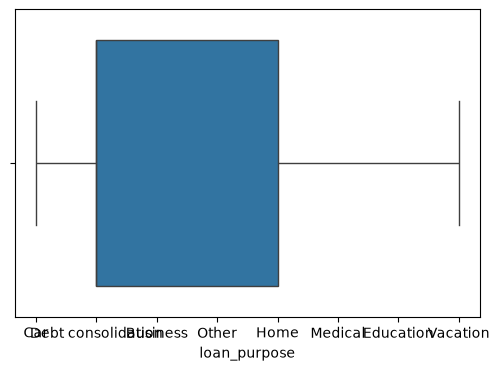

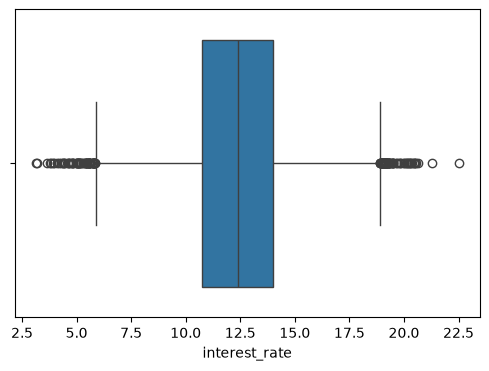

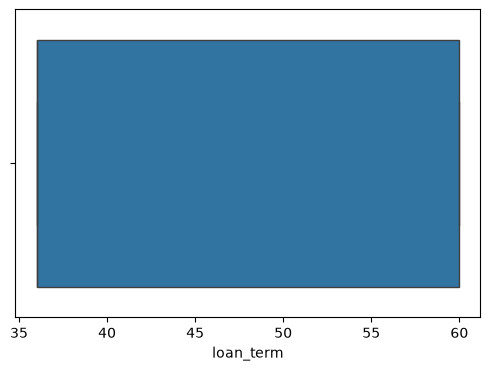

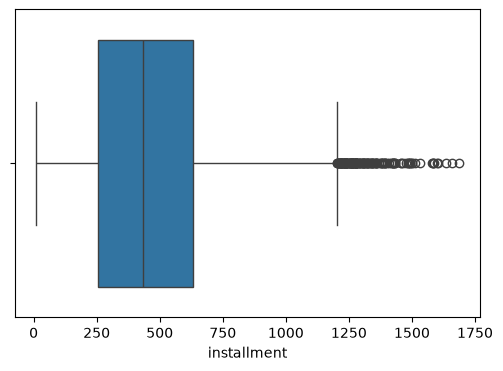

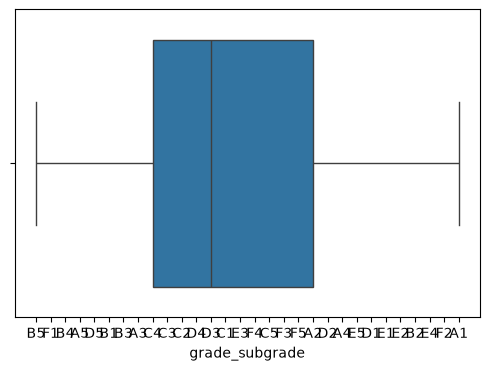

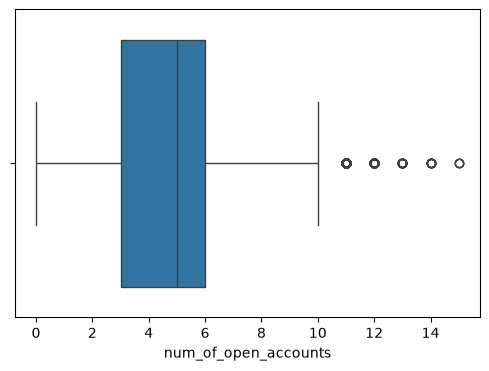

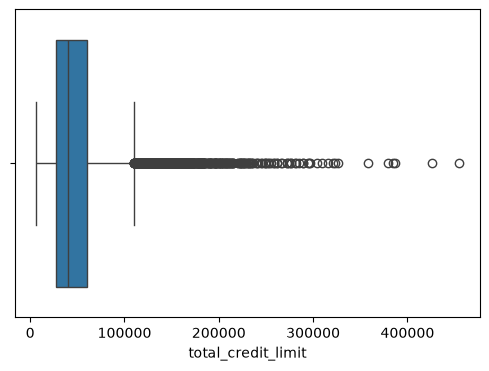

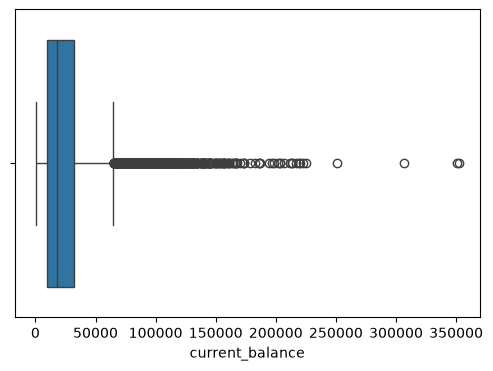

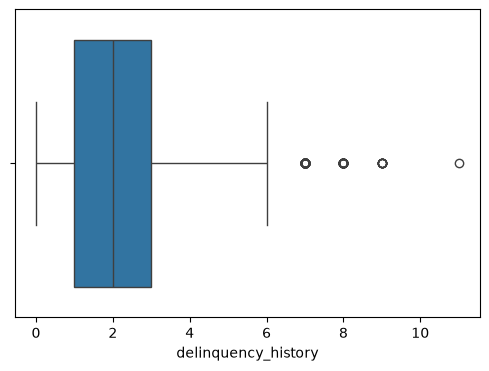

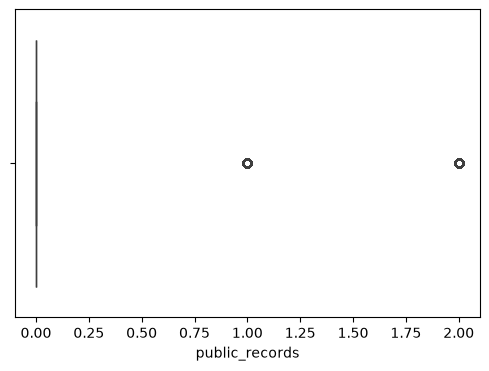

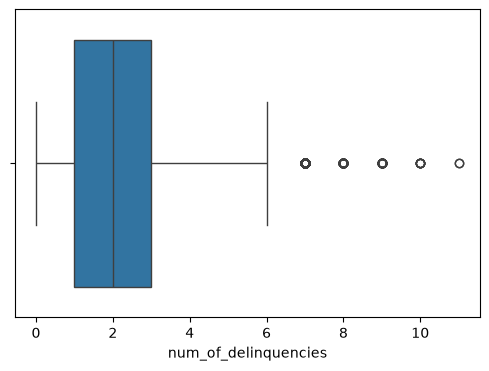

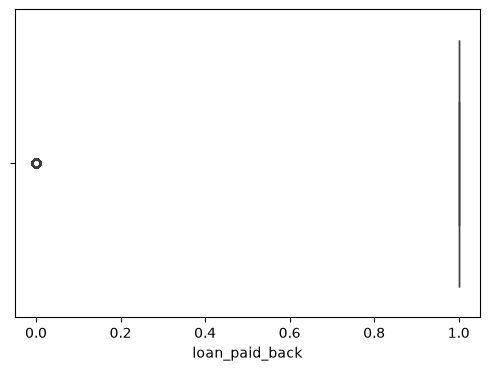

In [27]:
for col in numerical_col:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

# Data cleaning and preprocessing

In [28]:
df_cleaned=df.copy()
df_cleaned

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,39,Female,Married,Bachelor's,39640.08,3303.34,Employed,0.275,691,16322.23,...,36,566.22,C5,2,23748.10,5801.45,1,0,4,0
19996,66,Female,Married,Bachelor's,32062.90,2671.91,Employed,0.367,758,16697.34,...,36,553.71,B5,8,49929.65,40901.31,3,0,3,1
19997,65,Female,Single,Master's,18642.02,1553.50,Student,0.106,751,23924.78,...,36,772.66,B4,3,13137.57,5075.67,1,0,2,1
19998,35,Male,Married,Master's,22181.39,1848.45,Retired,0.275,646,16920.13,...,36,595.36,D2,5,19580.82,3876.16,4,0,5,1


In [29]:
df_cleaned.head()

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [30]:
df_cleaned.shape

(20000, 22)

In [31]:
df_cleaned.drop_duplicates(inplace=True)

In [32]:
df_cleaned.shape

(20000, 22)

In [33]:
df_cleaned.dtypes

age                       int64
gender                      str
marital_status              str
education_level             str
annual_income           float64
monthly_income          float64
employment_status           str
debt_to_income_ratio    float64
credit_score              int64
loan_amount             float64
loan_purpose                str
interest_rate           float64
loan_term                 int64
installment             float64
grade_subgrade              str
num_of_open_accounts      int64
total_credit_limit      float64
current_balance         float64
delinquency_history       int64
public_records            int64
num_of_delinquencies      int64
loan_paid_back            int64
dtype: object

In [34]:
df_cleaned["grade_subgrade"].value_counts()

grade_subgrade
C3    1514
C4    1463
C2    1436
C5    1422
C1    1410
D1    1155
D3    1146
D4    1100
D2    1091
D5    1073
B2     654
B1     620
B5     604
B3     599
B4     598
E4     378
E3     346
F5     340
E1     337
E2     321
F4     316
E5     313
F1     309
F2     299
F3     287
A5     190
A3     186
A2     182
A4     161
A1     150
Name: count, dtype: int64

# Feature engineering and extraction


In [35]:
df_cleaned['age_group']=pd.cut(df_cleaned['age'],bins=[0,20,30,40,50,60,70,80,90],
                                                      labels=["Below 20","20-30","30-40","40-50","50-60","60-70","70-80","Above 80"])
df_cleaned

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back,age_group
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,581.88,B5,7,40833.47,24302.07,1,0,1,1,50-60
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,573.17,F1,5,27968.01,10803.01,1,0,3,1,70-80
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,76.32,B4,2,15502.25,4505.44,0,0,0,1,40-50
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,468.07,A5,7,18157.79,5525.63,4,0,5,1,30-40
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,395.50,D5,1,17467.56,3593.91,2,0,2,1,60-70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,39,Female,Married,Bachelor's,39640.08,3303.34,Employed,0.275,691,16322.23,...,566.22,C5,2,23748.10,5801.45,1,0,4,0,30-40
19996,66,Female,Married,Bachelor's,32062.90,2671.91,Employed,0.367,758,16697.34,...,553.71,B5,8,49929.65,40901.31,3,0,3,1,60-70
19997,65,Female,Single,Master's,18642.02,1553.50,Student,0.106,751,23924.78,...,772.66,B4,3,13137.57,5075.67,1,0,2,1,60-70
19998,35,Male,Married,Master's,22181.39,1848.45,Retired,0.275,646,16920.13,...,595.36,D2,5,19580.82,3876.16,4,0,5,1,30-40


In [36]:
df_cleaned["income_group"] = pd.cut(
    df_cleaned["annual_income"],
    bins=[0, 30000, 60000, 100000, float('inf')],
    labels=["Low", "Medium", "High", "Very High"]
)
df_cleaned

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back,age_group,income_group
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,B5,7,40833.47,24302.07,1,0,1,1,50-60,Low
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,F1,5,27968.01,10803.01,1,0,3,1,70-80,Low
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,B4,2,15502.25,4505.44,0,0,0,1,40-50,Low
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,A5,7,18157.79,5525.63,4,0,5,1,30-40,Low
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,D5,1,17467.56,3593.91,2,0,2,1,60-70,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,39,Female,Married,Bachelor's,39640.08,3303.34,Employed,0.275,691,16322.23,...,C5,2,23748.10,5801.45,1,0,4,0,30-40,Medium
19996,66,Female,Married,Bachelor's,32062.90,2671.91,Employed,0.367,758,16697.34,...,B5,8,49929.65,40901.31,3,0,3,1,60-70,Medium
19997,65,Female,Single,Master's,18642.02,1553.50,Student,0.106,751,23924.78,...,B4,3,13137.57,5075.67,1,0,2,1,60-70,Low
19998,35,Male,Married,Master's,22181.39,1848.45,Retired,0.275,646,16920.13,...,D2,5,19580.82,3876.16,4,0,5,1,30-40,Low


# Encoding

In [37]:
selected_columns = [
    'employment_status',
    'debt_to_income_ratio',
    'credit_score',
    'loan_purpose',
    'interest_rate',
    'installment',
    'grade_subgrade',
    'num_of_open_accounts',
    'total_credit_limit',
    'delinquency_history',
    'public_records',
    'num_of_delinquencies'
]
df_model = df[selected_columns + ['loan_paid_back']]
df_encoded = pd.get_dummies(
    df_model,
    drop_first=True,
    dtype=int
)
df_encoded

,debt_to_income_ratio,credit_score,interest_rate,installment,num_of_open_accounts,total_credit_limit,delinquency_history,public_records,num_of_delinquencies,loan_paid_back,...,grade_subgrade_E1,grade_subgrade_E2,grade_subgrade_E3,grade_subgrade_E4,grade_subgrade_E5,grade_subgrade_F1,grade_subgrade_F2,grade_subgrade_F3,grade_subgrade_F4,grade_subgrade_F5
0,0.074,743,13.39,581.88,7,40833.47,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,0.219,531,17.81,573.17,5,27968.01,1,0,3,1,...,0,0,0,0,0,1,0,0,0,0
2,0.234,779,9.53,76.32,2,15502.25,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,0.264,809,7.99,468.07,7,18157.79,4,0,5,1,...,0,0,0,0,0,0,0,0,0,0
4,0.260,663,15.20,395.50,1,17467.56,2,0,2,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,0.275,691,15.05,566.22,2,23748.10,1,0,4,0,...,0,0,0,0,0,0,0,0,0,0
19996,0.367,758,11.89,553.71,8,49929.65,3,0,3,1,...,0,0,0,0,0,0,0,0,0,0
19997,0.106,751,10.06,772.66,3,13137.57,1,0,2,1,...,0,0,0,0,0,0,0,0,0,0
19998,0.275,646,16.06,595.36,5,19580.82,4,0,5,1,...,0,0,0,0,0,0,0,0,0,0


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score,f1_score,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [39]:
X=df_encoded.drop("loan_paid_back",axis=1)
y=df_encoded["loan_paid_back"]

In [40]:
X_train,X_test,y_train,y_test,=train_test_split(X,y,stratify=y,test_size=0.2,random_state=42)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [41]:
models={"LogisticRegression":LogisticRegression(),"KNN":KNeighborsClassifier(),"Naive Bayes":GaussianNB(),
        "DecisionTree":DecisionTreeClassifier(),"SVM (RBF Kernel)":SVC(probability=True)}

In [42]:
results=[]

In [43]:
for name,model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred=model.predict(X_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)
    results.append({'Model':name,'Accuracy':round(acc,4),'F1_Score':round(f1,4)})
results

[{'Model': 'LogisticRegression', 'Accuracy': 0.887, 'F1_Score': 0.9318},
 {'Model': 'KNN', 'Accuracy': 0.866, 'F1_Score': 0.9203},
 {'Model': 'Naive Bayes', 'Accuracy': 0.6455, 'F1_Score': 0.7315},
 {'Model': 'DecisionTree', 'Accuracy': 0.8417, 'F1_Score': 0.9006},
 {'Model': 'SVM (RBF Kernel)', 'Accuracy': 0.8925, 'F1_Score': 0.9362}]

In [44]:
import joblib
joblib.dump(models['SVM (RBF Kernel)'],'SVMRBF_project.pkl')
joblib.dump(scaler,'scaler_project.pkl')
joblib.dump(X.columns.tolist(),'columns_project.pkl')

['columns_project.pkl']